# Dataset Gallery

Load the staged image datasets through the canonical `mp_data` loaders and display train plus test/reference samples. Run this notebook from anywhere inside the repo checkout.

In [3]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
for candidate in (repo_root, *repo_root.parents):
    if (candidate / "src").is_dir() and (candidate / "prototyping").is_dir():
        repo_root = candidate
        break
else:
    raise RuntimeError("Could not find repo root from the current working directory.")

src_root = repo_root / "src"
for path in (repo_root, src_root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

data_root = repo_root / "data"
print("repo_root:", repo_root)
print("data_root:", data_root)

repo_root: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_par
data_root: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_par/data


In [4]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

from mp_config import clone_config, get_base_config
from mp_data import build_data_bundle

torch.set_grad_enabled(False)

N_SHOW = 12
SEED = 0

DATASETS = [
    {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 256,
        "image_channels": 3,
    },
     {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 128,
        "image_channels": 3,
    },
     {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 64,
        "image_channels": 3,
    },
    {
        "title": "CelebA32 Grayscale",
        "dataset": "celeba32_grey",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 32,
        "image_channels": 1,
    },
    {
        "title": "AFHQ-v2 Animal Faces",
        "dataset": "afhq_v2",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 64,
        "image_channels": 3,
    },
    {
        "title": "FFHQ-128 Faces",
        "dataset": "ffhq128",
        "train_label": "seeded train partition",
        "reference_label": "seeded reference partition",
        "reference_split": "seeded_partition",
        "allow_same_source_reference": True,
        "image_size": 256,
        "image_channels": 3,
    },
]

In [5]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

from mp_config import clone_config, get_base_config
from mp_data import build_data_bundle

torch.set_grad_enabled(False)

N_SHOW = 12
SEED = 0

DATASETS = [
    {
        "title": "Oxford Flowers102",
        "dataset": "flowers102",
        "train_label": "train",
        "reference_label": "test",
        "reference_split": "test",
        "image_size": 256,
        "image_channels": 3,
    },
    {
        "title": "FFHQ-128 Faces",
        "dataset": "ffhq128",
        "train_label": "seeded train partition",
        "reference_label": "seeded reference partition",
        "reference_split": "seeded_partition",
        "allow_same_source_reference": True,
        "image_size": 256,
        "image_channels": 3,
    },
]

In [6]:
def build_gallery_config(spec, n_show=N_SHOW):
    config = clone_config(get_base_config())
    config.data.dataset = spec["dataset"]
    config.data.root = str(data_root)
    config.data.download = False
    config.data.n_train = int(n_show)
    config.data.n_eval = int(n_show)
    config.data.image_size = int(spec["image_size"])
    config.data.image_channels = int(spec["image_channels"])
    config.data.resize_size = int(spec.get("resize_size", spec["image_size"]))
    config.data.flatten = False
    config.data.train_split = spec.get("train_split", "train")
    config.data.reference_split = spec["reference_split"]
    config.data.allow_same_source_reference = bool(
        spec.get("allow_same_source_reference", False)
    )
    config.training.seed = int(SEED)
    return config


def unnormalize_for_display(tensor):
    tensor = tensor.detach().cpu().clamp(-1.0, 1.0).add(1.0).div(2.0)
    if tensor.shape[1] == 1:
        tensor = tensor.repeat(1, 3, 1, 1)
    return tensor


def make_display_grid(tensor, nrow=6):
    grid = make_grid(unnormalize_for_display(tensor), nrow=nrow, padding=2)
    return grid.permute(1, 2, 0).numpy()


def summarize_bundle(spec, bundle):
    print(spec["title"])
    print("  train shape     :", tuple(bundle["train"].shape))
    print("  reference shape :", tuple(bundle["reference"].shape))
    print("  train source    :", bundle["train_source_id"])
    print("  reference source:", bundle["reference_source_id"])
    labels = bundle.get("train_labels")
    if labels is not None:
        print("  train labels    :", labels[: min(12, labels.numel())].tolist())
    print("  validation      :", bundle.get("data_validation"))
    print()


def plot_train_reference(spec, bundle):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    panels = [
        ("train", spec["train_label"], bundle["train"]),
        ("reference", spec["reference_label"], bundle["reference"]),
    ]
    for ax, (_, title, tensor) in zip(axes, panels):
        ax.imshow(make_display_grid(tensor))
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(spec["title"], fontsize=15)
    fig.tight_layout()
    plt.show()

Oxford Flowers102
  train shape     : (12, 3, 256, 256)
  reference shape : (12, 3, 256, 256)
  train source    : torchvision_flowers102:train
  reference source: torchvision_flowers102:test
  train labels    : [70, 59, 71, 60, 70, 50, 21, 66, 42, 17, 84, 24]
  validation      : {'train_source_id': 'torchvision_flowers102:train', 'reference_source_id': 'torchvision_flowers102:test', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}



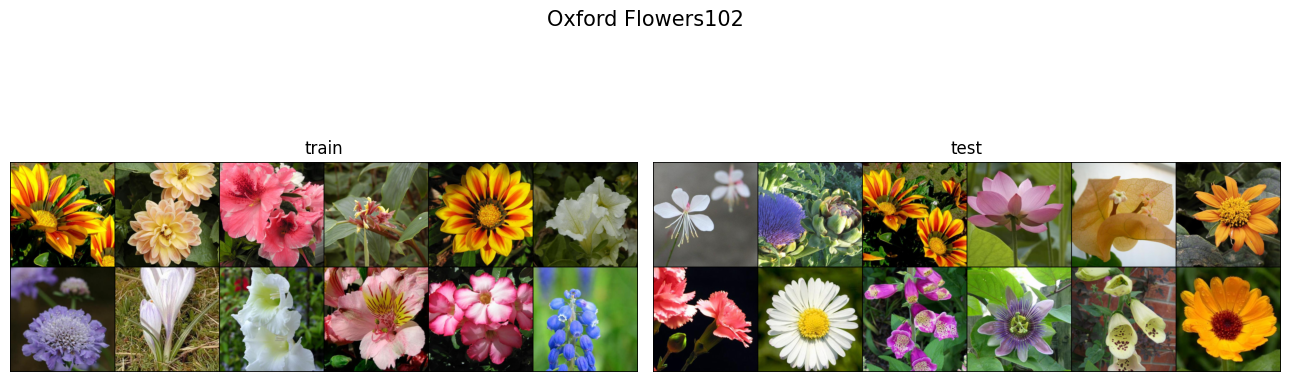

FFHQ-128 Faces
  train shape     : (12, 3, 256, 256)
  reference shape : (12, 3, 256, 256)
  train source    : ffhq128:all
  reference source: ffhq128:all
  train labels    : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  validation      : {'train_source_id': 'ffhq128:all', 'reference_source_id': 'ffhq128:all', 'train_role': 'train', 'reference_role': 'same_corpus_holdout', 'same_source': True, 'same_source_allowed': True, 'overlap_checked': True, 'overlap_count': 0}



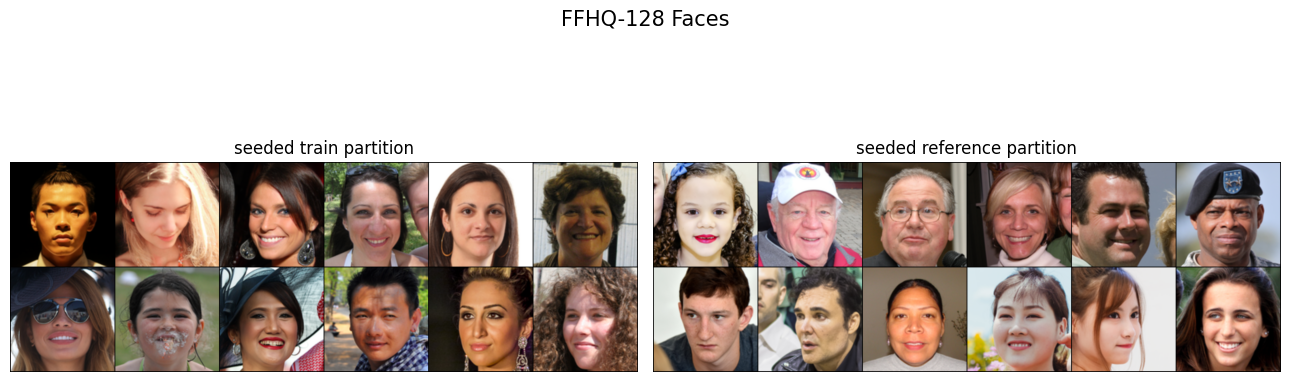

In [7]:
bundles = {}

for spec in DATASETS:
    config = build_gallery_config(spec)
    bundle = build_data_bundle(config)
    bundles[spec["dataset"]] = bundle
    summarize_bundle(spec, bundle)
    plot_train_reference(spec, bundle)

Notes:

- Flowers102, CelebA, and AFHQ-v2 use their explicit train/test-style splits here.
- FFHQ does not ship with an official train/test split in this staged format, so the loader displays a seeded train partition and a disjoint seeded reference partition from the same 70k-image corpus.


## How to use a canonical data bundle

The gallery above shows images, but the runner code consumes a **bundle**: a plain Python dictionary returned by `build_data_bundle(config)`. The important habit is to treat `train` as the optimizer-visible finite training set and `reference` as held-out data for evaluation/memorization comparisons.

Every loader returns the same high-level contract, whether the dataset is MNIST, CelebA32, Flowers102, AFHQ, FFHQ, or the synthetic GMM. That keeps runners boring: build config, call `build_data_bundle(config)`, pass `bundle["train"]` to training, and pass `bundle["reference"]` to metrics.


In [9]:
from mp_config import clone_config, get_base_config
from mp_data import build_data_bundle

# Start from the canonical config so the bundle has the same shape runners expect.
config = clone_config(get_base_config())

# Pick one supported dataset. The Image32 runner currently exposes these:
#   "mnist", "celeba32_grey", "flowers102", "afhq_v2", "ffhq128"
config.data.dataset = "mnist"

# Local data now lives at repo-root data/. This path is gitignored so downloads
# stay on disk without becoming part of commits.
config.data.root = str(data_root)
config.data.download = False  # Set True only if you intentionally want a download.

# Keep this cell lightweight: small deterministic subsets are enough to inspect
# bundle structure. Balanced MNIST subsets must be divisible by 10 classes.
config.data.n_train = 20
config.data.n_eval = 20
config.data.image_size = 32
config.data.image_channels = 1
config.data.flatten = False
config.data.balance_train_classes = True
config.data.balance_reference_classes = True

# Build once. The dispatcher calls the dataset-specific loader and then applies
# leakage guards that check train/reference source identity and index overlap.
bundle = build_data_bundle(config)



### What is inside `bundle`?

Required fields:

- `train`: tensor used by the optimizer. Image datasets usually return `[B, C, H, W]`; vector datasets return `[B, D]`.
- `reference`: held-out tensor used for evaluation/memorization comparisons, not optimization.
- `train_source_id` and `reference_source_id`: stable source names used by leakage guards.

Common optional fields:

- `train_labels`, `reference_labels`: labels aligned with the train/reference tensors when labels exist.
- `train_indices`, `reference_indices`: source indices for deterministic replay and overlap checks.
- `train_class_counts`, `reference_class_counts`: class-balance summaries for labeled image datasets.
- `display_shape`: original image shape for plotting utilities.
- `data_validation`: leakage-guard report added by `validate_data_bundle(...)`.
- `geometry`: synthetic-only planted structure, such as GMM basis, means, and latent variables.

The dictionary is intentionally boring. Runners should not need to know whether MNIST came from torchvision tensors or AFHQ came from recursive image folders; they just consume the shared keys.


In [10]:
def tensor_summary(tensor):
    """Small JSON-friendly summary for notebook display."""
    if tensor is None:
        return None
    values = tensor.detach().cpu().float()
    return {
        "shape": tuple(tensor.shape),
        "dtype": str(tensor.dtype),
        "min": float(values.min().item()),
        "max": float(values.max().item()),
        "mean": float(values.mean().item()),
    }


def preview_tensor(tensor, limit=10):
    """Preview labels/indices without dumping the whole subset."""
    if tensor is None:
        return None
    return tensor.detach().cpu().flatten()[:limit].tolist()


def describe_bundle(bundle):
    """Inspect the bundle contract without assuming a specific dataset."""
    return {
        "keys": sorted(bundle.keys()),
        "train": tensor_summary(bundle.get("train")),
        "reference": tensor_summary(bundle.get("reference")),
        "train_labels_preview": preview_tensor(bundle.get("train_labels")),
        "reference_labels_preview": preview_tensor(bundle.get("reference_labels")),
        "train_indices_preview": preview_tensor(bundle.get("train_indices")),
        "reference_indices_preview": preview_tensor(bundle.get("reference_indices")),
        "train_source_id": bundle.get("train_source_id"),
        "reference_source_id": bundle.get("reference_source_id"),
        "display_shape": bundle.get("display_shape"),
        "data_validation": bundle.get("data_validation"),
    }


describe_bundle(bundle)


{'keys': ['balanced_reference_classes',
  'balanced_train_classes',
  'class_balance_adjustments',
  'data_validation',
  'display_shape',
  'reference',
  'reference_class_counts',
  'reference_indices',
  'reference_labels',
  'reference_role',
  'reference_source_id',
  'reference_split',
  'requested_balanced_reference_classes',
  'requested_balanced_train_classes',
  'train',
  'train_class_counts',
  'train_indices',
  'train_labels',
  'train_role',
  'train_source_id',
  'train_split'],
 'train': {'shape': (20, 1, 32, 32),
  'dtype': 'torch.float32',
  'min': -1.0,
  'max': 1.0,
  'mean': -0.7153722047805786},
 'reference': {'shape': (20, 1, 32, 32),
  'dtype': 'torch.float32',
  'min': -1.0,
  'max': 1.0,
  'mean': -0.7181206345558167},
 'train_labels_preview': [4, 2, 6, 2, 1, 0, 5, 3, 3, 6],
 'reference_labels_preview': [4, 6, 0, 2, 5, 3, 8, 2, 1, 3],
 'train_indices_preview': [31574,
  34573,
  6464,
  47658,
  41019,
  11911,
  16471,
  49117,
  59299,
  42080],
 'reference


### How runners typically use it

The train/reference split is the main semantic boundary:

- Use `bundle["train"]` for optimizer updates.
- Use `bundle["reference"]` as the empirical held-out baseline for metrics.
- Save `train_indices`, `reference_indices`, and `data_validation` with artifacts when reproducibility matters.
- Use `display_shape` only for visualization; training should rely on the tensor shape itself.

For memorization metrics, compare generated samples against the finite training tensor, then compare held-out reference samples against the same training tensor as a baseline. That gives `f_mem` and nearest-neighbor-ratio numbers a sanity anchor.


In [11]:
from mp_metrics import compute_memorization_metrics

train = bundle["train"]
reference = bundle["reference"]

# Example baseline: how close does held-out data already sit to train?
# Generated samples should be interpreted relative to this baseline, not alone.
count = min(16, reference.shape[0])
baseline_memory = compute_memorization_metrics(
    reference[:count],
    train,
    chunk_size=128,
    config=config,
)

baseline_memory


{'ratio_threshold': 0.5,
 'n_samples': 16,
 'n_reference': 20,
 'f_mem': 0.0,
 'mean_nn_ratio': 0.8849955201148987,
 'std_nn_ratio': 0.10046815872192383,
 'mean_d1': 15.091296195983887,
 'mean_d2': 16.984405517578125}


### Dataset-specific notes

- MNIST returns labels and can enforce balanced train/reference class counts.
- CelebA32 returns identity labels from torchvision and uses fixed grayscale preprocessing.
- Flowers102 and folder-style image collections return class labels or synthetic folder labels depending on source layout.
- Synthetic GMM returns `geometry`, which is why the synthetic runner can compute planted-distribution metrics that image datasets cannot.

If a bundle fails to build, first check `config.data.root`, `config.data.download`, split names, and whether `n_train`/`n_eval` exceeds the local dataset size.



## Concrete image bundle recipes: clarity before DRY

The cells below are intentionally repetitive. Each one spells out the config fields that matter for a specific dataset so it is easy to copy a cell into a runner, tweak one knob, and know exactly what changed.

Use these as concrete recipes rather than a compact abstraction:

- **CelebA32 a la Bonnaire**: grayscale, center-cropped, resized to 32x32, matching the current UNet prototype scale.
- **AFHQ-v2 animals**: higher-resolution RGB animal faces from train/test folders.
- **Flowers102**: higher-resolution RGB flower images through the torchvision loader.
- **FFHQ faces**: higher-resolution RGB face thumbnails with a seeded same-corpus holdout.



### CelebA32 grayscale, Bonnaire-style UNet scale

This is the small image setting we have been using for the current UNet prototype: one channel, 32x32, centered face crop, normalized to `[-1, 1]`. The loader itself owns the CelebA crop/resize/grayscale transform, so the notebook config stays short.


CelebA32 grayscale, Bonnaire-style
  train shape     : (12, 1, 32, 32)
  reference shape : (12, 1, 32, 32)
  train source    : torchvision_celeba:train
  reference source: torchvision_celeba:valid
  train labels    : [9884, 658, 9361, 4319, 413, 9571, 9754, 7914, 7572, 4884, 7962, 6532]
  validation      : {'train_source_id': 'torchvision_celeba:train', 'reference_source_id': 'torchvision_celeba:valid', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}



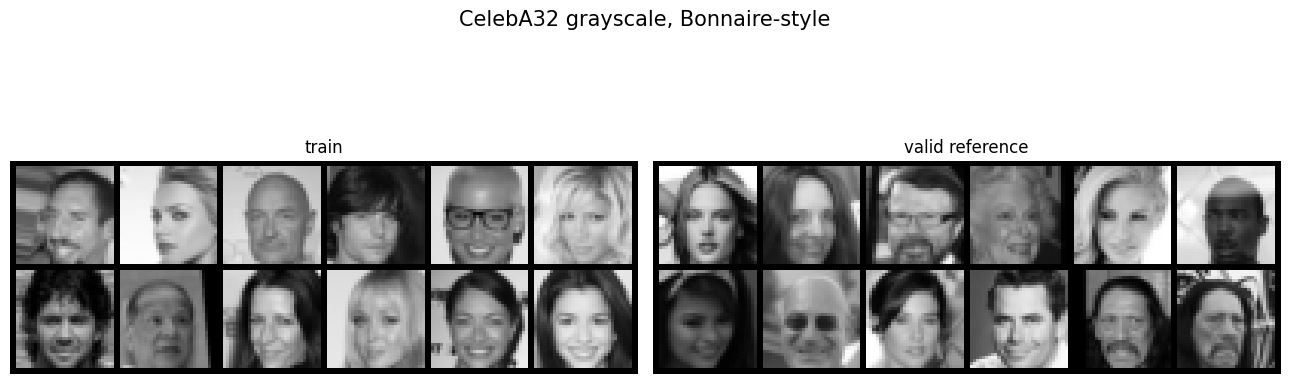

In [12]:
# CelebA32 / Bonnaire-style grayscale bundle.
#
# Why this shape:
# - 1 channel keeps the empirical image experiment close to the historical
#   grayscale CelebA32 setup.
# - 32x32 matches the current lightweight UNet prototype scale.
# - train/reference use different torchvision CelebA splits, so the leakage
#   guard expects different source IDs.
celeba32_config = clone_config(get_base_config())
celeba32_config.data.dataset = "celeba32_grey"
celeba32_config.data.root = str(data_root)
celeba32_config.data.download = False
celeba32_config.data.n_train = N_SHOW
celeba32_config.data.n_eval = N_SHOW
celeba32_config.data.image_size = 32
celeba32_config.data.image_channels = 1
celeba32_config.data.flatten = False
celeba32_config.data.reference_split = "valid"
celeba32_config.data.allow_same_source_reference = False
celeba32_config.training.seed = SEED

celeba32_bundle = build_data_bundle(celeba32_config)

celeba32_spec = {
    "title": "CelebA32 grayscale, Bonnaire-style",
    "train_label": "train",
    "reference_label": "valid reference",
}
summarize_bundle(celeba32_spec, celeba32_bundle)
plot_train_reference(celeba32_spec, celeba32_bundle)



### AFHQ-v2 animal faces, high-resolution RGB

AFHQ is useful for animal-face structure: cats, dogs, and wildlife with fairly aligned crops. Here we use RGB and a larger square crop so the gallery shows the visual regime we would eventually want for higher-resolution Image32/Image128-style experiments.


AFHQ-v2 animal faces, RGB 128
  train shape     : (12, 3, 128, 128)
  reference shape : (12, 3, 128, 128)
  train source    : afhq_v2:train
  reference source: afhq_v2:test
  train labels    : [2, 1, 2, 0, 0, 0, 1, 2, 2, 2, 1, 1]
  validation      : {'train_source_id': 'afhq_v2:train', 'reference_source_id': 'afhq_v2:test', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}



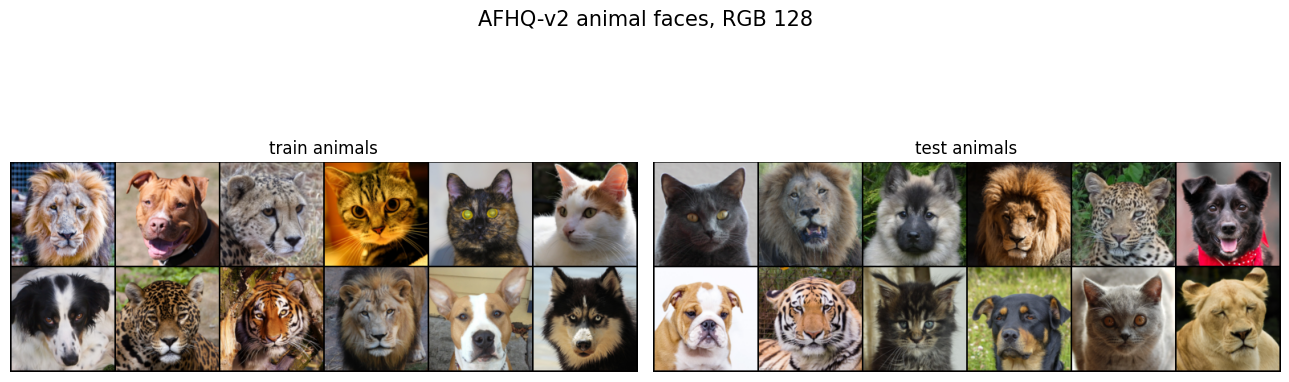

In [13]:
# AFHQ-v2 animal faces, high-resolution RGB.
#
# The loader uses ImageFolder under data/afhq_v2/{train,test}. Labels come
# from folder names. This makes it a nice sanity check for class-balanced or
# class-aware diagnostics later, even though the runner currently treats labels
# as metadata only.
afhq_highres_config = clone_config(get_base_config())
afhq_highres_config.data.dataset = "afhq_v2"
afhq_highres_config.data.root = str(data_root)
afhq_highres_config.data.dataset_subdir = "afhq_v2"
afhq_highres_config.data.download = False
afhq_highres_config.data.train_split = "train"
afhq_highres_config.data.reference_split = "test"
afhq_highres_config.data.allow_same_source_reference = False
afhq_highres_config.data.n_train = N_SHOW
afhq_highres_config.data.n_eval = N_SHOW
afhq_highres_config.data.image_size = 128
afhq_highres_config.data.resize_size = 128
afhq_highres_config.data.image_channels = 3
afhq_highres_config.data.flatten = False
afhq_highres_config.training.seed = SEED

afhq_highres_bundle = build_data_bundle(afhq_highres_config)

afhq_highres_spec = {
    "title": "AFHQ-v2 animal faces, RGB 128",
    "train_label": "train animals",
    "reference_label": "test animals",
}
summarize_bundle(afhq_highres_spec, afhq_highres_bundle)
plot_train_reference(afhq_highres_spec, afhq_highres_bundle)



### Oxford Flowers102, high-resolution RGB

Flowers are less face-aligned and more texture/color heavy than CelebA or AFHQ. This is a good stress case for whether memorization metrics are responding to image identity rather than just a clean face manifold.


Oxford Flowers102, RGB 256
  train shape     : (12, 3, 256, 256)
  reference shape : (12, 3, 256, 256)
  train source    : torchvision_flowers102:train
  reference source: torchvision_flowers102:test
  train labels    : [70, 59, 71, 60, 70, 50, 21, 66, 42, 17, 84, 24]
  validation      : {'train_source_id': 'torchvision_flowers102:train', 'reference_source_id': 'torchvision_flowers102:test', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}



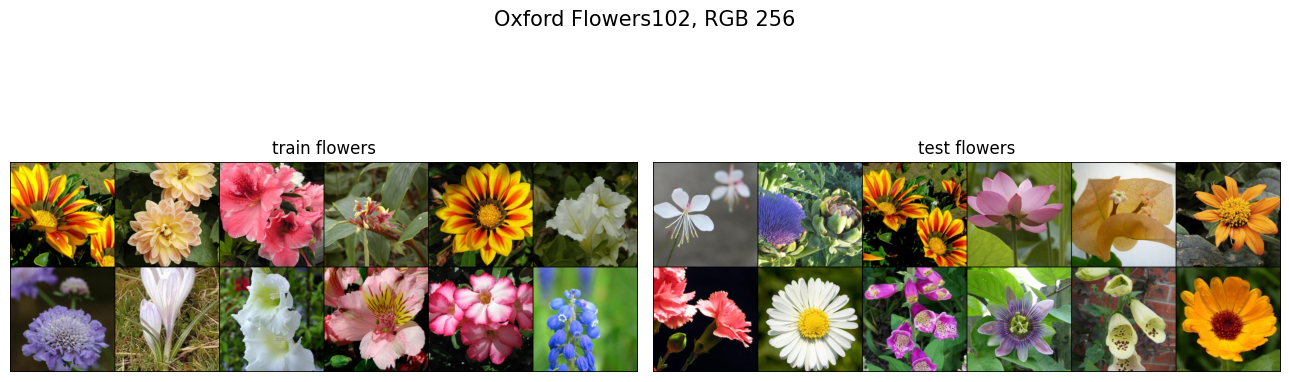

In [14]:
# Oxford Flowers102, high-resolution RGB.
#
# torchvision exposes train/val/test splits. We use train vs test here to make
# the held-out role obvious. If you want a smaller validation-style probe, set
# reference_split = "val" instead.
flowers_highres_config = clone_config(get_base_config())
flowers_highres_config.data.dataset = "flowers102"
flowers_highres_config.data.root = str(data_root)
flowers_highres_config.data.download = False
flowers_highres_config.data.train_split = "train"
flowers_highres_config.data.reference_split = "test"
flowers_highres_config.data.allow_same_source_reference = False
flowers_highres_config.data.n_train = N_SHOW
flowers_highres_config.data.n_eval = N_SHOW
flowers_highres_config.data.image_size = 256
flowers_highres_config.data.resize_size = 256
flowers_highres_config.data.image_channels = 3
flowers_highres_config.data.flatten = False
flowers_highres_config.training.seed = SEED

flowers_highres_bundle = build_data_bundle(flowers_highres_config)

flowers_highres_spec = {
    "title": "Oxford Flowers102, RGB 256",
    "train_label": "train flowers",
    "reference_label": "test flowers",
}
summarize_bundle(flowers_highres_spec, flowers_highres_bundle)
plot_train_reference(flowers_highres_spec, flowers_highres_bundle)



### FFHQ faces, high-resolution RGB same-corpus holdout

FFHQ thumbnails are staged locally as one image collection rather than official train/test folders. The loader therefore draws a seeded train subset and a disjoint seeded reference subset from the same source. That is why `allow_same_source_reference=True` is required here: the leakage guard checks index disjointness instead of source-name difference.


FFHQ face thumbnails, RGB 128
  train shape     : (12, 3, 128, 128)
  reference shape : (12, 3, 128, 128)
  train source    : ffhq128:all
  reference source: ffhq128:all
  train labels    : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  validation      : {'train_source_id': 'ffhq128:all', 'reference_source_id': 'ffhq128:all', 'train_role': 'train', 'reference_role': 'same_corpus_holdout', 'same_source': True, 'same_source_allowed': True, 'overlap_checked': True, 'overlap_count': 0}



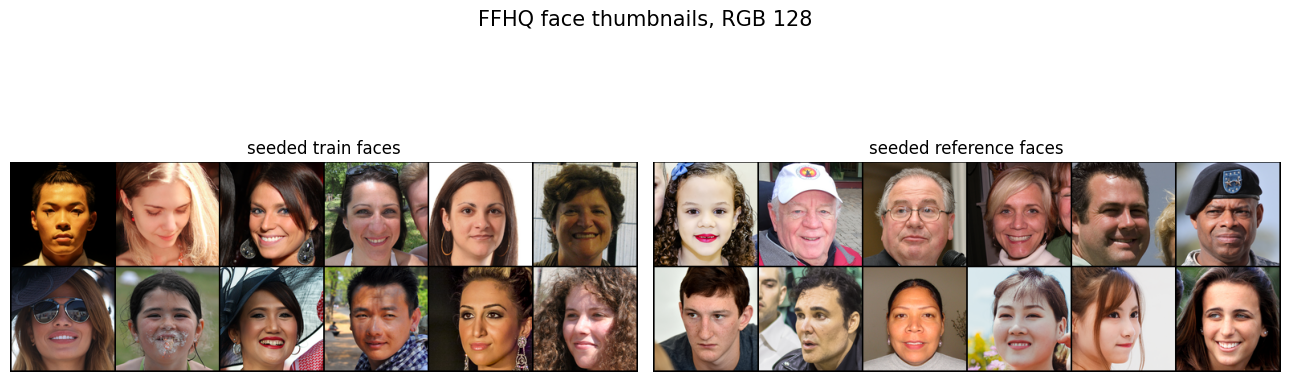

In [15]:
# FFHQ face thumbnails, high-resolution RGB.
#
# Important distinction from CelebA/AFHQ/Flowers:
# - train and reference have the same source ID: "ffhq128:all".
# - disjointness comes from non-overlapping seeded indices.
# - allow_same_source_reference=True tells the validation guard that this is
#   intentional and should be checked by index overlap.
ffhq_highres_config = clone_config(get_base_config())
ffhq_highres_config.data.dataset = "ffhq128"
ffhq_highres_config.data.root = str(data_root)
ffhq_highres_config.data.dataset_subdir = "ffhq/thumbnails128x128"
ffhq_highres_config.data.download = False
ffhq_highres_config.data.train_split = "seeded_partition"
ffhq_highres_config.data.reference_split = "seeded_partition"
ffhq_highres_config.data.allow_same_source_reference = True
ffhq_highres_config.data.n_train = N_SHOW
ffhq_highres_config.data.n_eval = N_SHOW
ffhq_highres_config.data.image_size = 128
ffhq_highres_config.data.resize_size = 128
ffhq_highres_config.data.image_channels = 3
ffhq_highres_config.data.flatten = False
ffhq_highres_config.training.seed = SEED

ffhq_highres_bundle = build_data_bundle(ffhq_highres_config)

ffhq_highres_spec = {
    "title": "FFHQ face thumbnails, RGB 128",
    "train_label": "seeded train faces",
    "reference_label": "seeded reference faces",
}
summarize_bundle(ffhq_highres_spec, ffhq_highres_bundle)
plot_train_reference(ffhq_highres_spec, ffhq_highres_bundle)



### Quick comparison table

This table is intentionally derived from the explicit cells above. It gives a compact final check without hiding how each bundle was constructed.


In [16]:
comparison_rows = []

for name, bundle in [
    ("celeba32_bonnaire", celeba32_bundle),
    ("afhq_animals_highres", afhq_highres_bundle),
    ("flowers_highres", flowers_highres_bundle),
    ("ffhq_faces_highres", ffhq_highres_bundle),
]:
    comparison_rows.append(
        {
            "name": name,
            "train_shape": tuple(bundle["train"].shape),
            "reference_shape": tuple(bundle["reference"].shape),
            "train_source_id": bundle["train_source_id"],
            "reference_source_id": bundle["reference_source_id"],
            "same_source": bundle["data_validation"]["same_source"],
            "overlap_checked": bundle["data_validation"]["overlap_checked"],
            "overlap_count": bundle["data_validation"]["overlap_count"],
        }
    )

comparison_rows


[{'name': 'celeba32_bonnaire',
  'train_shape': (12, 1, 32, 32),
  'reference_shape': (12, 1, 32, 32),
  'train_source_id': 'torchvision_celeba:train',
  'reference_source_id': 'torchvision_celeba:valid',
  'same_source': False,
  'overlap_checked': False,
  'overlap_count': None},
 {'name': 'afhq_animals_highres',
  'train_shape': (12, 3, 128, 128),
  'reference_shape': (12, 3, 128, 128),
  'train_source_id': 'afhq_v2:train',
  'reference_source_id': 'afhq_v2:test',
  'same_source': False,
  'overlap_checked': False,
  'overlap_count': None},
 {'name': 'flowers_highres',
  'train_shape': (12, 3, 256, 256),
  'reference_shape': (12, 3, 256, 256),
  'train_source_id': 'torchvision_flowers102:train',
  'reference_source_id': 'torchvision_flowers102:test',
  'same_source': False,
  'overlap_checked': False,
  'overlap_count': None},
 {'name': 'ffhq_faces_highres',
  'train_shape': (12, 3, 128, 128),
  'reference_shape': (12, 3, 128, 128),
  'train_source_id': 'ffhq128:all',
  'reference_s